# Deep Q-Learning for Cart Pole (PyTorch)

In this notebook, we will use Deep Q-Learning to solve Cart Pole.


Environment: (https://gymnasium.farama.org/environments/classic_control/cart_pole/).

Paper: (https://arxiv.org/abs/1312.5602).

## Setup

In [1]:
import gymnasium as gym
import math
import random
import matplotlib.pyplot as plt
import numpy as np
import os

Importing PyTorch neural network (torch.nn) and optimizer (torch.optim)

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

## Setup environment
To create MountainCar-v0 environment.

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Observing the environment

In [4]:
actions = ["Accelerate to the left", "Don’t accelerate", "Accelerate to the right"]
print ("Actions:", actions)

Actions: ['Accelerate to the left', 'Don’t accelerate', 'Accelerate to the right']


## Building a Deep Q-learning agent (off-policy)

![alt_text](https://lh3.googleusercontent.com/d/1zH2nQKEgT--Mm2-8zrepEue0I2aggWhk)

## Experience Replay Buffer

We will use **Experience Replay** in order to store the agent's experiences in the form $(s_t, a_t, r_t, s_{t+1})$:
- **state** $s_t$ in which the agent was in
- **action** $a_t$ the agent selected in that state
- **reward** $r_t$ received for taking the action in the state
- **next state** $s_{t+1}$ that the agent arrived to after action

After collecting a number **N** of these tuples $(s_t, a_t, r_t, s_{t+1})$, we randomly pass the data to train network.

In [5]:
class ReplayBuffer:
    def __init__(self, max_length, observation_space_n):

        self.index, self.size, self.max_length = 0, 0, max_length

        self.states = np.zeros((max_length, observation_space_n), dtype=np.float32)
        self.actions = np.zeros((max_length), dtype=np.uint8)
        self.rewards = np.zeros((max_length), dtype=np.float32)
        self.next_states = np.zeros((max_length, observation_space_n), dtype=np.float32)
        self.dones = np.zeros((max_length), dtype=np.uint8)

    def __len__(self):
        return self.size

    def update(self, state, action, reward, next_state, is_terminal):
        # Update the Replay Buffer
        self.states[self.index] = state
        self.actions[self.index] = action
        self.rewards[self.index] = reward
        self.next_states[self.index] = next_state
        self.dones[self.index] = is_terminal

        self.index = (self.index + 1) % self.max_length
        if self.size < self.max_length:
            self.size += 1

    def sample(self, batch_size):
        # Pick indexes randomly from the Replay Buffer
        idxs = np.random.randint(0, self.size, size=batch_size)

        return (self.states[idxs], self.actions[idxs], self.rewards[idxs], self.next_states[idxs], self.dones[idxs])

## Funções auxiliares para calcular recompensa mais informativa

In [ ]:
def mountaincar_potential(state, scale=1000.0):
    position, velocity = state

    kinetic = 0.5 * velocity**2 # energia cinética
    potential = (0.0025 / 3.0) * np.sin(3.0 * position) # potencial gravitacional

    return scale * (kinetic + potential)


def shaped_reward(
    state,
    reward,
    next_state,
    terminated,
    gamma,
    scale=1000.0
):
    phi_state = mountaincar_potential(state, scale)

    # Terminal states must have zero potential.
    phi_next = (
        0.0 if terminated
        else mountaincar_potential(next_state, scale)
    )

    return reward + gamma * phi_next - phi_state

## Linear Neural Network

A linear neural network to be used with Deep Q-learning algoritmh. It is useful for environments where we are not receiving an image as observation.

The input size of the network receives an input of the available environment states.

The output of the network is the Q-value for each available action. So the output size is the shape of the actions state.

The size of the hidden layers is arbitrary. So, it can be varied from one application to another and it is one of the parameters that are worth modifying to ensure greater efficiency in the network.

In [6]:
class LinearNetwork(nn.Module):
    """
    Linear neural network for Deep Q-learning
    """
    def __init__(self, observation_space_n, action_space_n):
        super(LinearNetwork, self).__init__()

        self.layers = nn.Sequential(
            nn.Linear(observation_space_n, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_space_n)
        )

    # Called with either one element to determine next action, or a batch during optimization
    # Returns tensor([[left0exp,right0exp]...]).
    def forward(self, state):
        return self.layers(state)

## Deep Q-learning Agent

In [7]:
class DeepQLearningAgent:

    def __init__(
        self,
        learning_rate: float,
        initial_epsilon: float,
        epsilon_decay: float,
        final_epsilon: float,
        discount_factor: float,
        batch_size: int,
        max_memory: int,
        observation_space: np.ndarray,
        action_space: int
    ):
        """Initialize a Reinforcement Learning agent with an empty dictionary
        of state-action values (q_values), a learning rate and an epsilon.

        Args:
            learning_rate: The learning rate
            initial_epsilon: The initial epsilon value
            epsilon_decay: The decay for epsilon
            final_epsilon: The final epsilon value
            discount_factor: The discount factor for computing the Q-value
            batch_size: The sample size for batch
            max_memory: The max number of iterations to be stored in memory buffer
            observation_space: The observation space
            action_space: The action space
        """
        self.learning_rate = learning_rate
        self.discount_factor = discount_factor
        self.epsilon = initial_epsilon
        self.epsilon_decay = epsilon_decay
        self.final_epsilon = final_epsilon
        self.batch_size = batch_size
        self.max_memory = max_memory
        self.observation_space = observation_space
        self.action_space = action_space
        self.training_error = []

        # Check that there is a GPU avaiable
        self.device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
        print(f"Using device ", self.device)

        # Initialize experience replay buffer
        self.memory = ReplayBuffer(self.max_memory, self.observation_space.shape[0])

        # Input and output size based on the Env
        # These lines establish the feed-forward part of the netwotk used to choose actions
        self.dqn = LinearNetwork(self.observation_space.shape[0], self.action_space.n).to(self.device)

        # Initialize optimizer
        self.optimizer = optim.Adam(self.dqn.parameters(), lr=self.learning_rate)

        print("Deep Q-learning agent started with PyTorch")

    def act(self, state):
        with torch.no_grad():
            state = torch.FloatTensor(state).to(self.device)
            action = self.dqn.forward(state).argmax(dim=-1)
            action = action.cpu().numpy()
            return action

    def choose_action(self, state):
        """
        Returns the best action with probability (1 - epsilon)
        otherwise a random action with probability epsilon to ensure exploration.
        """
        # with probability epsilon return a random action to explore the environment
        if np.random.random() < self.epsilon:
            return self.action_space.sample()
        # with probability (1 - epsilon) act greedily (exploit)
        else:
            return self.act(state)

    def remember(self, state, action, reward, new_state, is_terminal):
        self.memory.update(state, action, reward, new_state, is_terminal)

    def update(self):
        # If we have less experience than batch size, we don't start training
        if self.batch_size * 10 > self.memory.size:
            return

        # A sample of the training experiences
        (states, actions, rewards, next_states, dones) = self.memory.sample(self.batch_size)

        # Turning the experiences into tensors
        states = torch.as_tensor(states).to(self.device)
        actions = torch.as_tensor(actions).to(self.device).unsqueeze(-1)
        rewards = torch.as_tensor(rewards).to(self.device).unsqueeze(-1)
        next_states = torch.as_tensor(next_states).to(self.device)
        dones = torch.as_tensor(dones).to(self.device).unsqueeze(-1)

        # Eval states
        Q1 = self.dqn.forward(states).gather(-1, actions.long())

        with torch.no_grad():
            # Eval next states
            Q2 = self.dqn.forward(next_states).max(dim=-1, keepdim=True)[0]
            target = (rewards + (1 - dones) * self.discount_factor * Q2).to(self.device)

        temporal_difference_loss = F.mse_loss(Q1, target)

        self.training_error.append(temporal_difference_loss.item())

        # Train the network using target and the predicted q_network values
        self.optimizer.zero_grad()
        temporal_difference_loss.backward()
        self.optimizer.step()

    def decay_epsilon(self):
        self.epsilon = max(
            self.final_epsilon,
            self.epsilon - self.epsilon_decay
        )

## Defining set of experiments

In [ ]:
# learning_rate = 1e-4 # @param {type:"number"}
# nb_max_episodes = 400 # @param {type:"integer"}
# start_epsilon = 1.0 # @param {type:"number"}
# epsilon_decay = start_epsilon / nb_max_episodes  # reduce the exploration over time
# final_epsilon = 0.1 # @param {type:"number"}
# discount_factor = 0.99 # @param {type:"number"}
# batch_size = 64 # @param {type:"integer"}
# max_memory = 10000 # @param {type:"integer"}
# total_steps = 0 # @param {type:"integer"}
# test_freq = 50 # @param {type:"integer"}
experiments = {
    "baseline": {
        "description": "Experimento de referência: DQN original com correção do tratamento de terminated/truncated. Treinamento de 400 episódios para estabelecer as métricas iniciais de desempenho.",
        "algorithm_version": "dqn_v1",
        "learning_rate": 1e-4,
        "nb_max_episodes": 400,
        "start_epsilon": 1.0,
        "final_epsilon": 0.1,
        "epsilon_decay": 1.0 / 400,
        "discount_factor": 0.99,
        "batch_size": 64,
        "max_memory": 10000,
        "test_freq": 50,
        "seed": 42,
    },
    # Hipótese: prolongar a exploração permitirá ao agente descobrir trajetórias melhores e utilizá-las para aprender uma política mais eficaz.
    "exp_01": {
        "description": "Investigar se o aumento de 400 para 2000 episódios, acompanhado de um decaimento mais lento de epsilon, permite maior exploração e melhora o desempenho do agente no MountainCar-v0.",
        "algorithm_version": "dqn_v1",
        "learning_rate": 1e-4,
        "nb_max_episodes": 2000,
        "start_epsilon": 1.0,
        "final_epsilon": 0.1,
        "epsilon_decay": 1.0 / 2000,
        "discount_factor": 0.99,
        "batch_size": 64,
        "max_memory": 10000,
        "test_freq": 50,
        "seed": 42,
    },
    "exp_02": {
        "description": "Investigar se reward shaping baseado na energia mecânica melhora o aprendizado do MountainCar, mantendo os hiperparâmetros do exp_01.",
        "algorithm_version": "dqn_v1_pbrs_energy",
        "learning_rate": 1e-4,
        "nb_max_episodes": 2000,
        "start_epsilon": 1.0,
        "final_epsilon": 0.1,
        "epsilon_decay": 1.0 / 2000,
        "discount_factor": 0.99,
        "batch_size": 64,
        "max_memory": 10000,
        "test_freq": 50,
        "seed": 42,
        "reward_shaping": "energy",
        "reward_scale": 1000.0,
    },
}

## Experiment Manager

In [ ]:
import json
import time
import random
from copy import deepcopy
from pathlib import Path

import pandas as pd
import numpy as np
import torch
import gymnasium as gym

from tqdm.auto import tqdm


class ExperimentManager:

    def __init__(self, environment, experiments, directory="Deep_Q_Learning_MountainCar"):
        self.environment = environment
        self.experiments = experiments
        self.directory = Path(directory)
        self.directory.mkdir(parents=True, exist_ok=True)

        self.results = {}

    def set_seed(self, seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

    def experiment_path(self, experiment_id):
        return self.directory / experiment_id

    def save_json(self, filename, data):
        with open(filename, "w") as f:
            json.dump(data, f, indent=4)

    def load_json(self, filename):
        with open(filename) as f:
            return json.load(f)

    def create_agent(self, config, env):
        return DeepQLearningAgent(
            learning_rate=config["learning_rate"],
            initial_epsilon=config["start_epsilon"],
            epsilon_decay=config["epsilon_decay"],
            final_epsilon=config["final_epsilon"],
            discount_factor=config["discount_factor"],
            batch_size=config["batch_size"],
            max_memory=config["max_memory"],
            observation_space=env.observation_space,
            action_space=env.action_space,
        )

    def evaluate(self, agent, seed, num_episodes=25):
        # Evaluation without epsilon-greedy exploration
        env = gym.make(self.environment)

        returns = []
        max_positions = []
        successes = 0

        try:
            for episode in range(num_episodes):
                state, info = env.reset(seed=seed + 10000 + episode)

                terminated = False
                truncated = False
                total_reward = 0
                max_position = float(state[0])

                while not (terminated or truncated):
                    action = int(agent.act(state))

                    state, reward, terminated, truncated, info = env.step(action)

                    total_reward += reward
                    max_position = max(max_position, float(state[0]))

                returns.append(float(total_reward))
                max_positions.append(max_position)

                if terminated:
                    successes += 1

        finally:
            env.close()

        return {
            "mean_reward": float(np.mean(returns)),
            "std_reward": float(np.std(returns)),
            "mean_max_position": float(np.mean(max_positions)),
            "max_position": float(np.max(max_positions)),
            "success_rate": float(successes / num_episodes),
            "num_episodes": num_episodes,
        }

    def run(self, experiment_id, force=False):
        config = deepcopy(self.experiments[experiment_id])
        path = self.experiment_path(experiment_id)

        config_file = path / "config.json"
        metrics_file = path / "metrics.json"
        model_file = path / "model.pt"

        # Reuse completed experiment when available
        if not force and all(
            p.exists() for p in [config_file, metrics_file, model_file]
        ):
            saved_config = self.load_json(config_file)

            if saved_config != config:
                raise ValueError(
                    f"Configuration changed for {experiment_id}. "
                    "Use a new experiment ID or force=True."
                )

            result = self.load_json(metrics_file)
            self.results[experiment_id] = result

            print(f"Loaded experiment: {experiment_id}")
            return result

        path.mkdir(parents=True, exist_ok=True)

        seed = config.get("seed", 42)
        self.set_seed(seed)

        env = gym.make(self.environment)
        env.action_space.seed(seed)

        agent = self.create_agent(config, env)

        metrics = {
            "rewards": [],
            "steps": [],
            "max_positions": [],
            "training_error": [],
            "evaluations": [],
            "total_steps": 0,
        }

        start_time = time.perf_counter()

        try:
            for episode in tqdm(
                range(config["nb_max_episodes"]),
                desc=experiment_id
            ):
                if episode == 0:
                    state, info = env.reset(seed=seed)
                else:
                    state, info = env.reset()

                terminated = False
                truncated = False
                total_reward = 0
                episode_steps = 0
                max_position = float(state[0])

                while not (terminated or truncated):
                    action = int(agent.choose_action(state))

                    next_state, reward, terminated, truncated, info = env.step(action)


                    training_reward = reward

                    if config.get("reward_shaping") == "energy":
                        training_reward = shaped_reward(
                            state=state,
                            reward=reward,
                            next_state=next_state,
                            terminated=terminated,
                            gamma=config["discount_factor"],
                            scale=config["reward_scale"]
                        )
                        
                    # Bootstrap is disabled only on true termination,
                    # not on TimeLimit truncation.
                    agent.remember(
                        state, action, training_reward, next_state, terminated
                    )

                    agent.update()

                    max_position = max(
                        max_position, float(next_state[0])
                    )

                    state = next_state
                    total_reward += reward
                    episode_steps += 1
                    metrics["total_steps"] += 1

                agent.decay_epsilon()

                metrics["rewards"].append(float(total_reward))
                metrics["steps"].append(episode_steps)
                metrics["max_positions"].append(max_position)

                if (episode + 1) % config["test_freq"] == 0:
                    evaluation = self.evaluate(agent, seed)

                    evaluation["episode"] = episode + 1
                    evaluation["total_steps"] = metrics["total_steps"]
                    evaluation["epsilon"] = float(agent.epsilon)

                    metrics["evaluations"].append(evaluation)

                    print(
                        f"\nEpisode {episode + 1} | "
                        f"Test reward: {evaluation['mean_reward']:.2f} | "
                        f"Max position: {evaluation['max_position']:.3f} | "
                        f"Mean max position: {evaluation['mean_max_position']:.3f} | "
                        f"Success: {evaluation['success_rate']:.1%}"
                    )
                    
            metrics["training_error"] = [
                float(value) for value in agent.training_error
            ]

            metrics["duration_seconds"] = (
                time.perf_counter() - start_time
            )

            # Independent final evaluation
            metrics["final_evaluation"] = self.evaluate(agent, seed)

            metrics["final_epsilon"] = float(agent.epsilon)

            # Save configuration, metrics and trained network
            torch.save(
                agent.dqn.state_dict(),
                model_file
            )

            self.save_json(config_file, config)
            self.save_json(metrics_file, metrics)

            self.results[experiment_id] = metrics

            print(f"Saved experiment: {experiment_id}")

            return metrics

        finally:
            env.close()

    def load(self, experiment_id):
        path = self.experiment_path(experiment_id)

        config = self.load_json(path / "config.json")
        metrics = self.load_json(path / "metrics.json")

        self.results[experiment_id] = metrics

        return {
            "config": config,
            "metrics": metrics,
        }

    def load_model(self, experiment_id):
        path = self.experiment_path(experiment_id)
        config = self.load_json(path / "config.json")

        env = gym.make(self.environment)

        try:
            agent = self.create_agent(config, env)

            state_dict = torch.load(
                path / "model.pt",
                map_location=agent.device,
                weights_only=True
            )

            agent.dqn.load_state_dict(state_dict)
            agent.dqn.eval()

            return agent

        finally:
            env.close()

    def compare(self, experiment_ids=None):
        if experiment_ids is None:
            experiment_ids = list(self.experiments.keys())

        rows = []

        for experiment_id in experiment_ids:
            path = self.experiment_path(experiment_id)

            required_files = ["config.json", "metrics.json", "model.pt"]

            if not all((path / filename).exists() for filename in required_files):
                continue

            result = self.load(experiment_id)
            config = result["config"]
            metrics = result["metrics"]
            evaluation = metrics["final_evaluation"]

            rows.append({
                "Experiment": experiment_id,
                "Episodes": config["nb_max_episodes"],
                "Learning Rate": config["learning_rate"],
                "Gamma": config["discount_factor"],
                "Batch Size": config["batch_size"],
                "Memory": config["max_memory"],
                "Epsilon Decay": config["epsilon_decay"],
                "Train Reward (Last 100)": np.mean(
                    metrics["rewards"][-100:]
                ),
                "Test Reward": evaluation["mean_reward"],
                "Max Position": evaluation["max_position"],
                "Mean Max Position": evaluation["mean_max_position"],
                "Success Rate": evaluation["success_rate"],
                "Total Steps": metrics["total_steps"],
                "Duration (s)": metrics["duration_seconds"],
            })

        return pd.DataFrame(rows)

### Test accurracy

## Playing and Training

In [10]:
manager = ExperimentManager(
    environment="MountainCar-v0",
    experiments=experiments
)

baseline = manager.run("baseline")

Using device  mps
Deep Q-learning agent started with PyTorch


baseline:  12%|█▎        | 50/400 [00:27<07:24,  1.27s/it]


Episode 50 | Test reward: -200.00 | Max position: -0.194 | Success: 0.0%


baseline:  25%|██▌       | 100/400 [00:58<06:24,  1.28s/it]


Episode 100 | Test reward: -200.00 | Max position: -0.406 | Success: 0.0%


baseline:  38%|███▊      | 150/400 [01:30<05:11,  1.25s/it]

... (8 outputs left out)


Episode 350 | Test reward: -200.00 | Max position: -0.406 | Success: 0.0%


baseline: 100%|██████████| 400/400 [04:08<00:00,  1.61it/s]


Episode 400 | Test reward: -200.00 | Max position: -0.406 | Success: 0.0%


Saved experiment: baseline


In [ ]:
from gymnasium.wrappers import RecordVideo


def record_experiment_video(manager, experiment_id, seed=42):
    agent = manager.load_model(experiment_id)
    path = manager.experiment_path(experiment_id)

    env = gym.make(
        manager.environment,
        render_mode="rgb_array"
    )

    recorded_env = RecordVideo(
        env,
        video_folder=str(path),
        name_prefix=f"evaluation-{experiment_id}",
        episode_trigger=lambda episode_id: episode_id == 0
    )

    try:
        state, info = recorded_env.reset(seed=seed)

        terminated = False
        truncated = False

        while not (terminated or truncated):
            action = int(agent.act(state))
            state, reward, terminated, truncated, info = recorded_env.step(action)

    finally:
        recorded_env.close()

In [12]:
record_experiment_video(manager, "baseline")

Using device  mps
Deep Q-learning agent started with PyTorch


/Users/gilcesarf/git/repositories/imd/imd1103-202602/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /Users/gilcesarf/git/repositories/imd/imd1103-202602/experimentos-unidade-2/Deep_Q_Learning_MountainCar/baseline folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


### Metrics

In [13]:
import matplotlib.pyplot as plt


def moving_average(values, window=100):
    values = np.asarray(values, dtype=float)

    return pd.Series(values).rolling(
        window=window,
        min_periods=1
    ).mean().to_numpy()


def plot_experiment(manager, experiment_id, rolling_length=100):
    result = manager.load(experiment_id)
    metrics = result["metrics"]

    fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
    axs = axs.flatten()

    rewards = metrics["rewards"]
    evaluations = metrics["evaluations"]
    steps = metrics["steps"]
    errors = metrics["training_error"]
    positions = metrics["max_positions"]

    axs[0].set_title("Training Reward")
    axs[0].set_xlabel("Episode")
    axs[0].set_ylabel("Reward")
    axs[0].plot(rewards, alpha=0.3)
    axs[0].plot(moving_average(rewards, rolling_length))

    axs[1].set_title("Test Reward")
    axs[1].set_xlabel("Episode")
    axs[1].set_ylabel("Reward")
    axs[1].plot(
        [e["episode"] for e in evaluations],
        [e["mean_reward"] for e in evaluations]
    )

    axs[2].set_title("Episode Length")
    axs[2].set_xlabel("Episode")
    axs[2].set_ylabel("Steps")
    axs[2].plot(moving_average(steps, rolling_length))

    axs[3].set_title("Training Error")
    axs[3].set_xlabel("Update")
    axs[3].set_ylabel("Loss")
    axs[3].plot(moving_average(errors, rolling_length))

    axs[4].set_title("Maximum Position")
    axs[4].set_xlabel("Episode")
    axs[4].set_ylabel("Position")
    axs[4].plot(positions, alpha=0.3)
    axs[4].plot(
        moving_average(positions, rolling_length),
        label="Moving Average"
    )
    axs[4].axhline(
        y=0.5, color="red", linestyle="--", label="Goal"
    )
    axs[4].legend()

    fig.delaxes(axs[5])
    fig.suptitle(experiment_id, fontsize=15)
    plt.tight_layout()

    path = manager.experiment_path(experiment_id)
    fig.savefig(path / "training.png", dpi=150)

    plt.show()


def plot_comparison(manager, experiment_ids, metric="max_positions",
                    rolling_length=100):
    plt.figure(figsize=(12, 5))

    for experiment_id in experiment_ids:
        result = manager.load(experiment_id)
        metrics = result["metrics"]

        if metric == "test_reward":
            x = [e["total_steps"] for e in metrics["evaluations"]]
            y = [e["mean_reward"] for e in metrics["evaluations"]]
        else:
            # Compare using environment steps, not episode count
            x = np.cumsum(metrics["steps"])
            y = moving_average(metrics[metric], rolling_length)

        plt.plot(x, y, label=experiment_id)

    if metric == "max_positions":
        plt.axhline(y=0.5, color="red", linestyle="--", label="Goal")

    plt.title(f"Experiment Comparison - {metric}")
    plt.xlabel("Total Environment Steps")
    plt.ylabel(metric)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

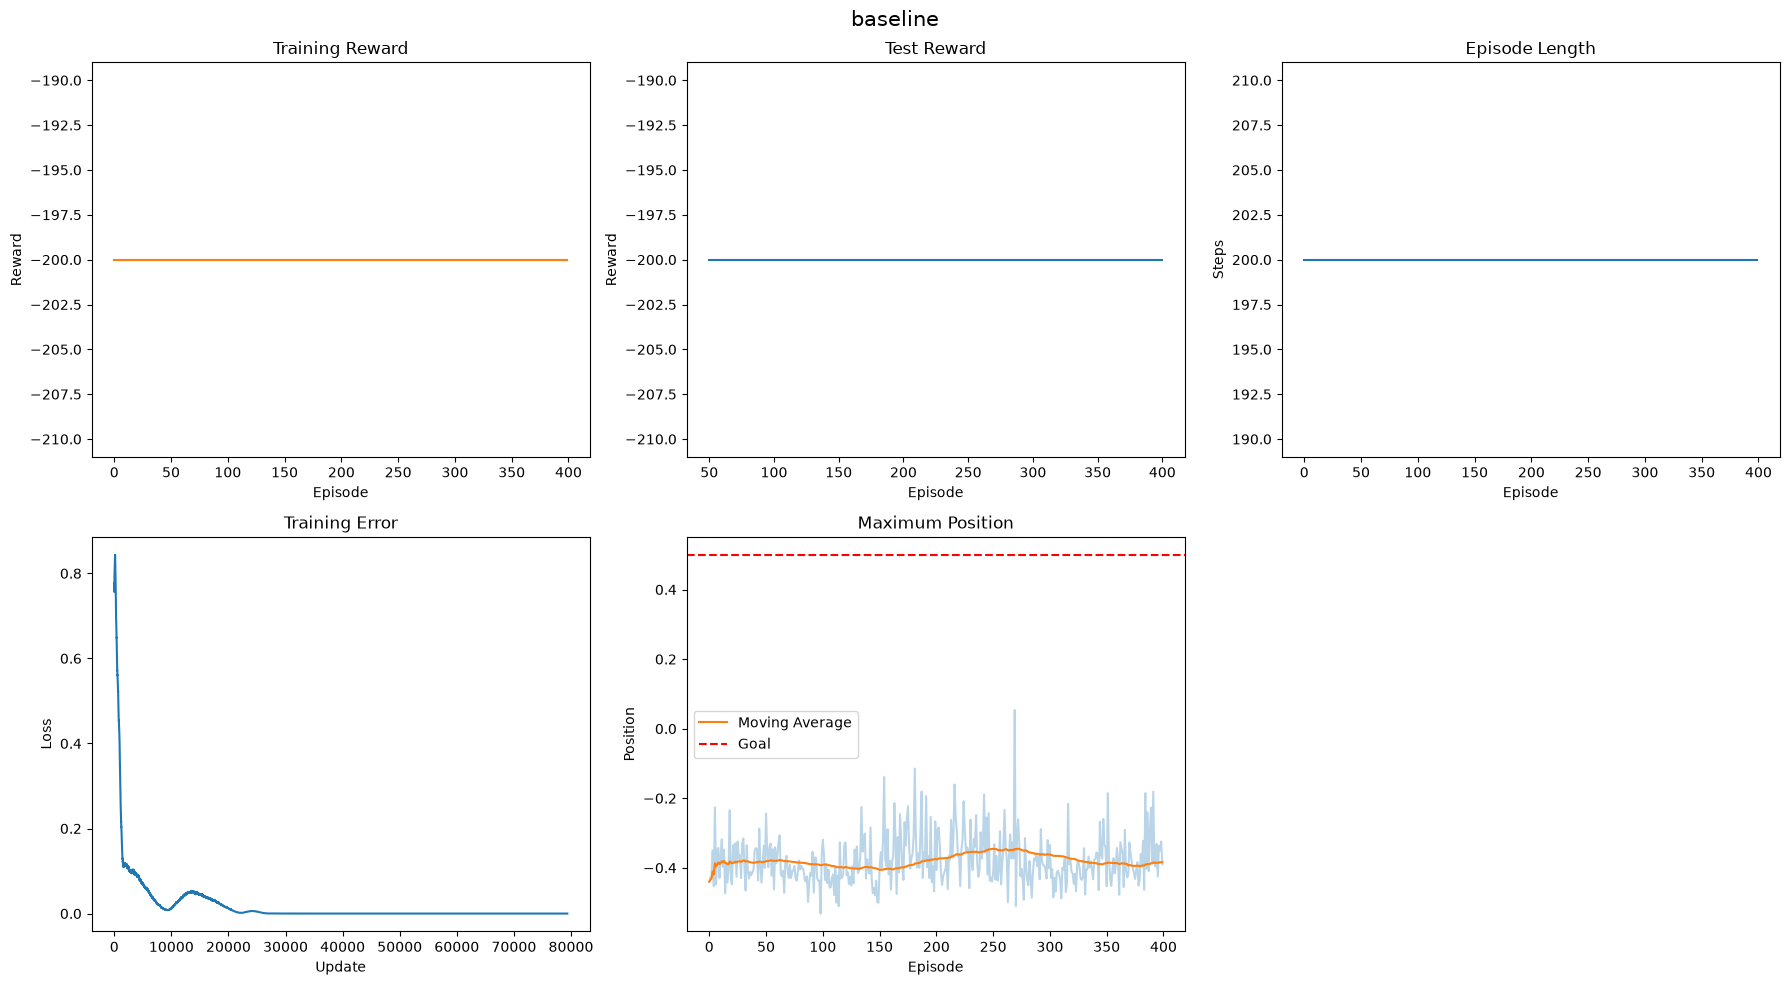

In [14]:
plot_experiment(manager, "baseline")

In [15]:
exp_01 = manager.run("exp_01")

Using device  mps
Deep Q-learning agent started with PyTorch


exp_01:   2%|▎         | 50/2000 [00:27<38:44,  1.19s/it]


Episode 50 | Test reward: -200.00 | Max position: -0.194 | Success: 0.0%


exp_01:   5%|▌         | 100/2000 [00:55<38:05,  1.20s/it]


Episode 100 | Test reward: -200.00 | Max position: -0.406 | Success: 0.0%


exp_01:   8%|▊         | 150/2000 [01:24<36:34,  1.19s/it]

... (72 outputs left out)


Episode 1950 | Test reward: -200.00 | Max position: -0.406 | Success: 0.0%


exp_01: 100%|██████████| 2000/2000 [20:11<00:00,  1.65it/s]


Episode 2000 | Test reward: -200.00 | Max position: -0.194 | Success: 0.0%


Saved experiment: exp_01


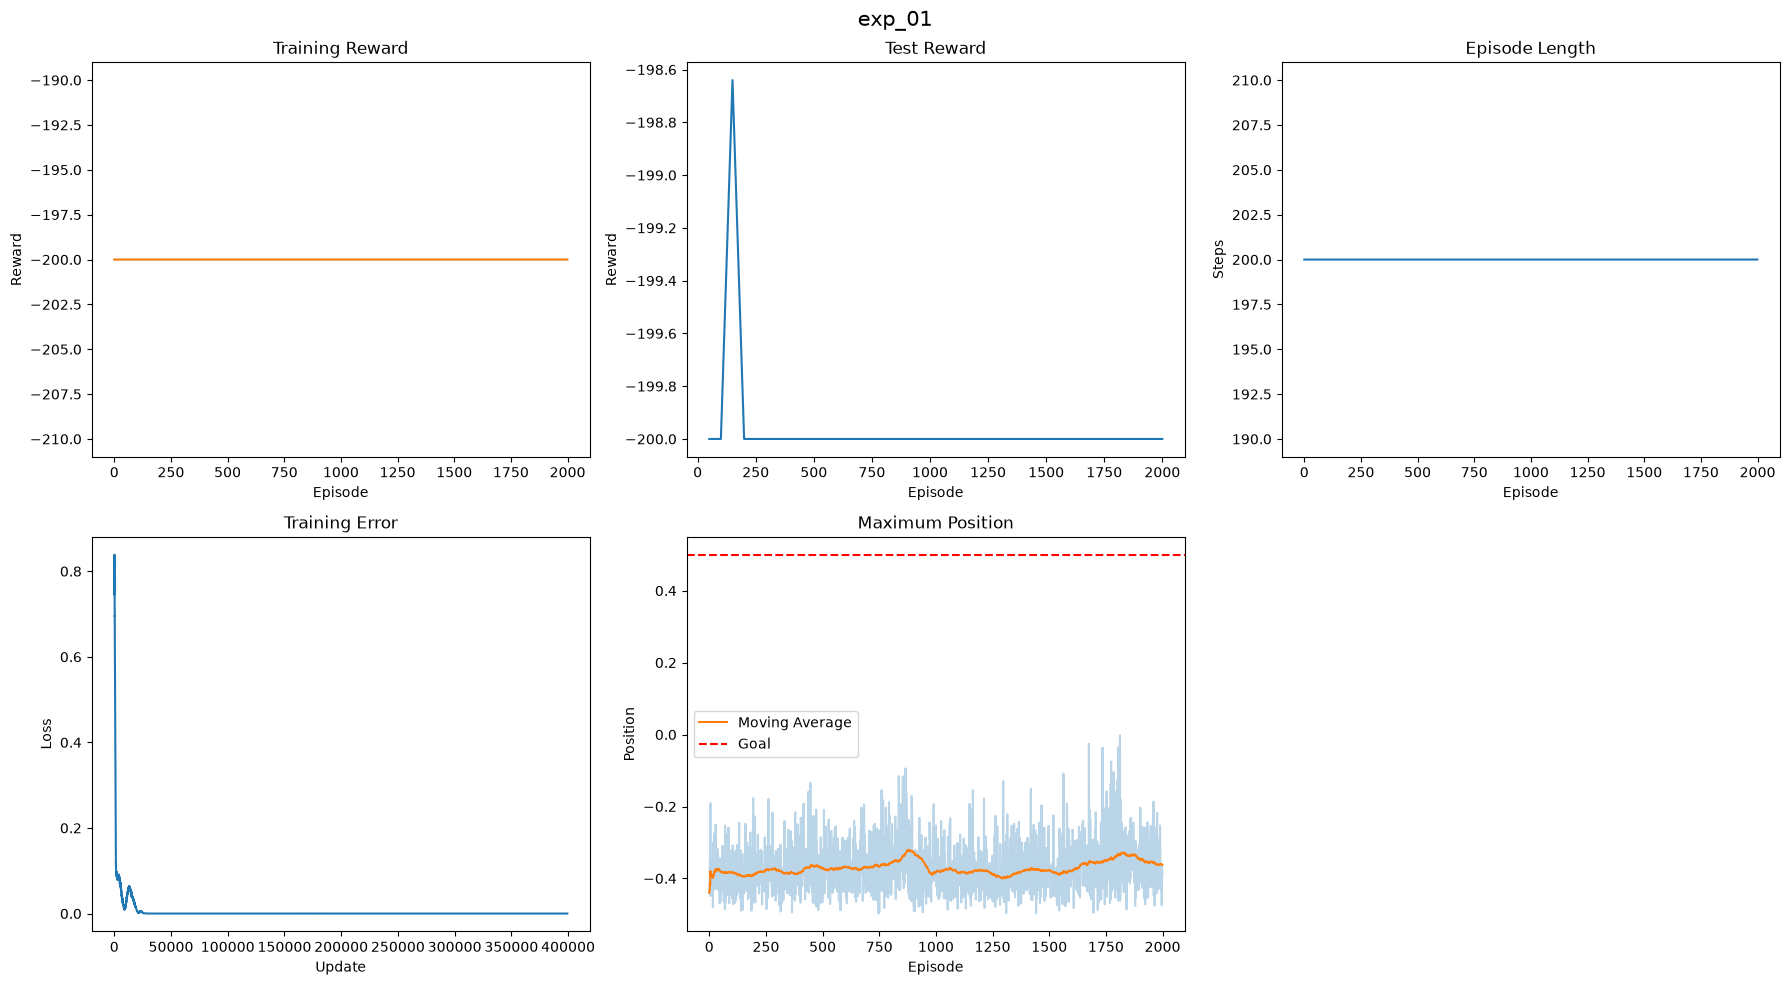

In [16]:
plot_experiment(manager, "exp_01")

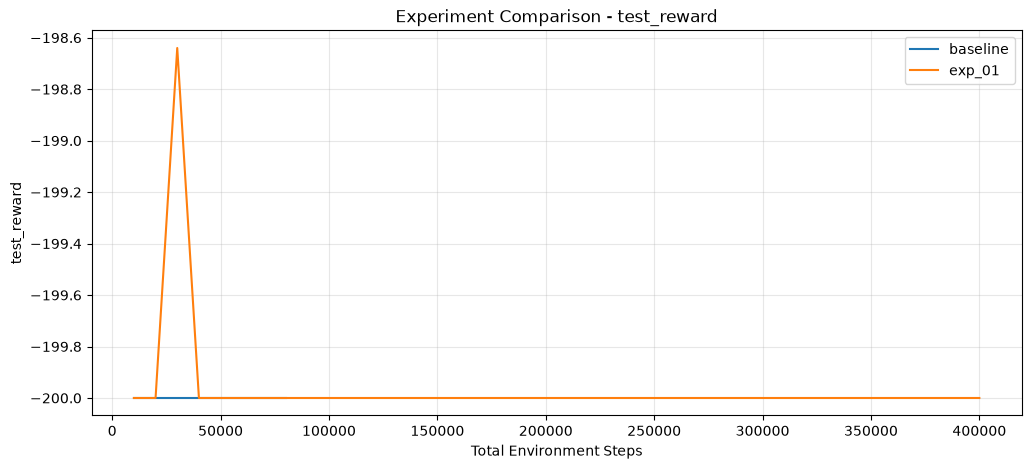

In [17]:
plot_comparison(
    manager,
    ["baseline", "exp_01"],
    metric="test_reward"
)

In [18]:
comparison = manager.compare()
display(comparison)

,Experiment,Episodes,Learning Rate,Gamma,Batch Size,Memory,Epsilon Decay,Train Reward (Last 100),Test Reward,Max Position,Mean Max Position,Success Rate,Total Steps,Duration (s)
0,baseline,400,0.0001,0.99,64,10000,0.0025,-200.0,-200.0,-0.405965,-0.484382,0.0,80000,248.349016
1,exp_01,2000,0.0001,0.99,64,10000,0.0005,-200.0,-200.0,-0.194262,-0.260915,0.0,400000,1211.220118


In [19]:
record_experiment_video(manager, "exp_01")

Using device  mps
Deep Q-learning agent started with PyTorch


/Users/gilcesarf/git/repositories/imd/imd1103-202602/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /Users/gilcesarf/git/repositories/imd/imd1103-202602/experimentos-unidade-2/Deep_Q_Learning_MountainCar/exp_01 folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


In [21]:
from IPython.display import HTML, display
from pathlib import Path
from base64 import b64encode

def display_experiment_video(manager, experiment_id):
    path = manager.experiment_path(experiment_id)
    video_file = path / "evaluation-episode-0.mp4"

    video = b64encode(video_file.read_bytes()).decode()

    return f"""
        <div style="flex: 1;">
            <h3>{experiment_id}</h3>
            <video width="100%" controls>
                <source src="data:video/mp4;base64,{video}" type="video/mp4">
            </video>
        </div>
    """

display(HTML(f"""
    <div style="display: flex; gap: 20px;">
        {display_experiment_video(manager, "baseline")}
        {display_experiment_video(manager, "exp_01")}
    </div>
"""))